# 1 · Data and stylised facts
Four assets, January 2018 to October 2026, adjusted daily closes from Yahoo Finance (snapshot in `data/`, refresh with `python scripts/fetch_data.py`):

| Series | Ticker | What it represents |
|---|---|---|
| Gold ETF | GLD | SPDR Gold Shares, USD |
| European equity ETF | C40.PA | Amundi CAC 40 UCITS ETF, EUR |
| Bitcoin | BTC-USD | trades 7 days a week |
| US equity | ^GSPC | S&P 500 index |

**Calendar alignment.** Bitcoin trades on weekends and the ETFs trade on different exchange calendars. Forward-filling missing days would create fake zero returns and bias volatility and correlation down, so joint analyses use only the days on which *all* series have a price. A Monday Bitcoin return then spans the whole weekend, which is the honest way to compare it with a Monday ETF return.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
FIG = pathlib.Path("../figures"); FIG.mkdir(exist_ok=True)
from fineco import data

In [2]:
raw = data.load_prices(common_days=False)
px = data.load_prices()
print("calendar days with any price:", len(raw), "| common trading days:", len(px))
print(raw.notna().sum())

calendar days with any price: 3225 | common trading days: 2199
bitcoin      3225
cac40_etf    2262
gold_etf     2220
sp500        2220
dtype: int64


In [3]:
r = data.log_returns(px)
data.summary_table(r)

,ann_mean_%,ann_vol_%,skew,excess_kurtosis,min_%,max_%,JB_pvalue,n
bitcoin,18.797,64.163,-0.897,11.564,-46.473,20.305,0.0,2198.0
cac40_etf,7.348,18.443,-0.744,10.411,-12.025,7.454,0.0,2198.0
gold_etf,11.979,17.190,-0.729,7.468,-10.841,6.165,0.0,2198.0
sp500,11.853,19.166,-0.629,15.080,-12.765,9.089,0.0,2198.0


All four series have fat tails (excess kurtosis well above 0) and negative skew; Jarque-Bera rejects normality for every one.

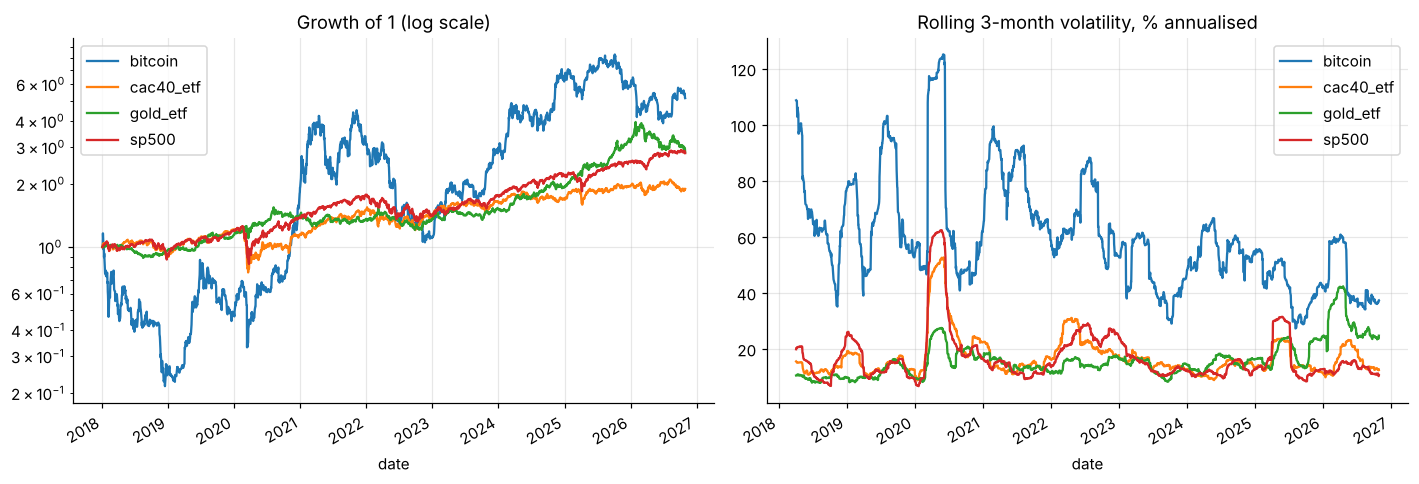

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(px / px.iloc[0]).plot(ax=axes[0], logy=True, title="Growth of 1 (log scale)")
(r.rolling(63).std() * np.sqrt(252) * 100).plot(ax=axes[1], title="Rolling 3-month volatility, % annualised")
plt.tight_layout(); plt.savefig(FIG / "01_prices_vol.png", bbox_inches="tight"); plt.show()

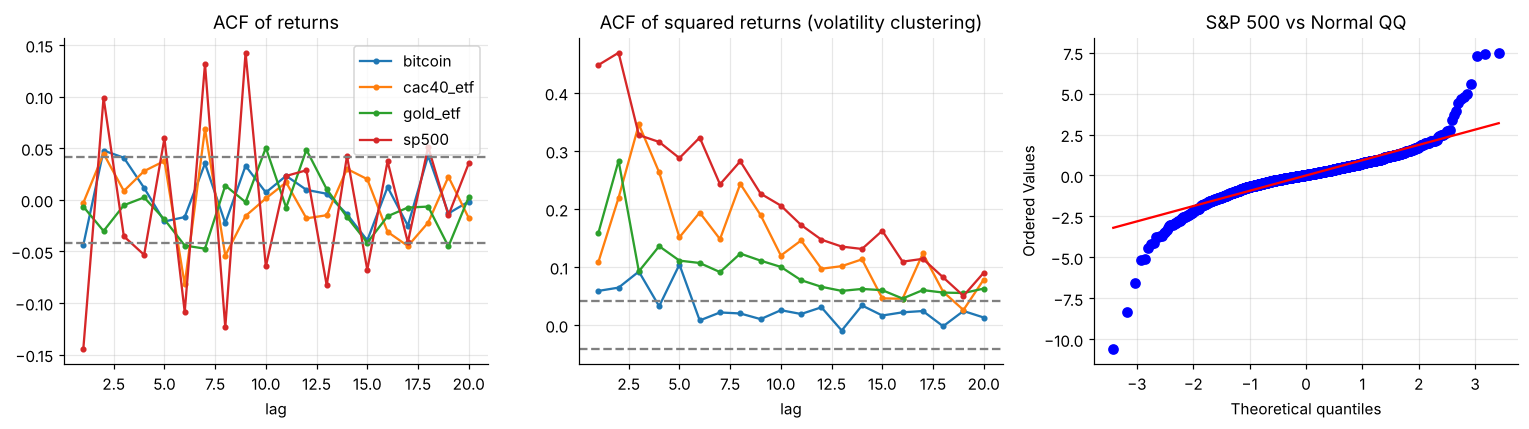

In [5]:
from scipy import stats
from statsmodels.tsa.stattools import acf
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for c in r:
    axes[0].plot(range(1, 21), acf(r[c], nlags=20)[1:], marker=".", label=c)
    axes[1].plot(range(1, 21), acf(r[c] ** 2, nlags=20)[1:], marker=".", label=c)
axes[0].set_title("ACF of returns"); axes[1].set_title("ACF of squared returns (volatility clustering)")
for ax in axes[:2]:
    ax.axhline(1.96 / np.sqrt(len(r)), ls="--", c="grey"); ax.axhline(-1.96 / np.sqrt(len(r)), ls="--", c="grey"); ax.set_xlabel("lag")
axes[0].legend()
stats.probplot((r["sp500"] - r["sp500"].mean()) / r["sp500"].std(), dist="norm", plot=axes[2])
axes[2].set_title("S&P 500 vs Normal QQ")
plt.tight_layout(); plt.savefig(FIG / "01_stylized_facts.png", bbox_inches="tight"); plt.show()

In [6]:
corr = pd.DataFrame({"full sample": r.corr().stack(),
                     "2020 crash (Feb-Apr)": r.loc["2020-02":"2020-04"].corr().stack(),
                     "2022 rate shock": r.loc["2022"].corr().stack()})
corr = corr[[a < b for a, b in corr.index]]
corr

full sample  2020 crash (Feb-Apr)  2022 rate shock
bitcoin   cac40_etf        0.197                 0.623            0.321
          gold_etf         0.136                 0.277            0.142
          sp500            0.299                 0.561            0.565
cac40_etf gold_etf         0.053                 0.382            0.068
          sp500            0.524                 0.727            0.510
gold_etf  sp500            0.133                 0.218            0.198

## Findings
* Over 2,199 common trading days every series is strongly non-normal: excess kurtosis runs from 7.5 (gold) to 15.1 (S&P 500), and all four are negatively skewed.
* Bitcoin's annualised volatility (64%) is more than three times that of the equity indices (18-19%) and gold (17%).
* Returns themselves show little autocorrelation, but squared returns stay positively autocorrelated for many lags. That volatility clustering is what notebook 3 models.
* Correlations jump in stress. CAC 40 vs S&P 500 rises from 0.52 over the full sample to 0.73 in the February-April 2020 crash, and Bitcoin vs S&P 500 from 0.30 to 0.56. Diversification is weakest exactly when it is needed, which notebook 5 quantifies with copulas.